# Delhi Air Quality Index (AQI) Analysis

Delhi, the capital of India, consistently ranks among the most polluted cities globally. This analysis explores a comprehensive hourly dataset of Delhi's air quality, aiming to uncover temporal patterns, critical pollutants, and the overall severity of air pollution during the observation period.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')

## Data Loading & Exploration

We load the hourly air quality dataset, setting the 'date' column as our datetime index to facilitate time-series analysis. We also perform an initial data quality check.

In [2]:
df = pd.read_csv(r'd:\project shadowfox\Level-2_Intermediate\data\delhiaqi.csv')
df['date'] = pd.to_datetime(df['date'])
df.set_index('date', inplace=True)

display(df.shape)
display(df.head())
display(df.describe())
df.info()
display(df.dtypes)
display(df.isnull().sum())

(561, 8)

,co,no,no2,o3,so2,pm2_5,pm10,nh3
date,,,,,,,,
2023-01-01 00:00:00,1655.58,1.66,39.41,5.90,17.88,169.29,194.64,5.83
2023-01-01 01:00:00,1869.20,6.82,42.16,1.99,22.17,182.84,211.08,7.66
2023-01-01 02:00:00,2510.07,27.72,43.87,0.02,30.04,220.25,260.68,11.40
2023-01-01 03:00:00,3150.94,55.43,44.55,0.85,35.76,252.90,304.12,13.55
2023-01-01 04:00:00,3471.37,68.84,45.24,5.45,39.10,266.36,322.80,14.19


,co,no,no2,o3,so2,pm2_5,pm10,nh3
count,561.000000,561.000000,561.000000,561.000000,561.000000,561.000000,561.000000,561.000000
mean,3814.942210,51.181979,75.292496,30.141943,64.655936,358.256364,420.988414,26.425062
std,3227.744681,83.904476,42.473791,39.979405,61.073080,227.359117,271.287026,36.563094
min,654.220000,0.000000,13.370000,0.000000,5.250000,60.100000,69.080000,0.630000
25%,1708.980000,3.380000,44.550000,0.070000,28.130000,204.450000,240.900000,8.230000
50%,2590.180000,13.300000,63.750000,11.800000,47.210000,301.170000,340.900000,14.820000
75%,4432.680000,59.010000,97.330000,47.210000,77.250000,416.650000,482.570000,26.350000
max,16876.220000,425.580000,263.210000,164.510000,511.170000,1310.200000,1499.270000,267.510000


<class 'pandas.DataFrame'>
DatetimeIndex: 561 entries, 2023-01-01 00:00:00 to 2023-01-24 08:00:00
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   co      561 non-null    float64
 1   no      561 non-null    float64
 2   no2     561 non-null    float64
 3   o3      561 non-null    float64
 4   so2     561 non-null    float64
 5   pm2_5   561 non-null    float64
 6   pm10    561 non-null    float64
 7   nh3     561 non-null    float64
dtypes: float64(8)
memory usage: 39.4 KB


co       float64
no       float64
no2      float64
o3       float64
so2      float64
pm2_5    float64
pm10     float64
nh3      float64
dtype: object

co       0
no       0
no2      0
o3       0
so2      0
pm2_5    0
pm10     0
nh3      0
dtype: int64

## AQI Calculation

We calculate the Air Quality Index (AQI) based on the Indian Central Pollution Control Board (CPCB) methodology. This involves computing a sub-index for each individual pollutant and defining the overall AQI as the maximum of these sub-indices. Finally, we classify the AQI into standardized categories.

In [3]:
def get_sub_index(val, bp):
    for b in bp:
        if val >= b[0] and val <= b[1]:
            return ((b[3] - b[2]) / (b[1] - b[0])) * (val - b[0]) + b[2]
    return 0

bp_pm25 = [(0, 30, 0, 50), (31, 60, 51, 100), (61, 90, 101, 200), (91, 120, 201, 300), (121, 250, 301, 400), (251, 10000, 401, 500)]
bp_pm10 = [(0, 50, 0, 50), (51, 100, 51, 100), (101, 250, 101, 200), (251, 350, 201, 300), (351, 430, 301, 400), (431, 10000, 401, 500)]
bp_so2 = [(0, 40, 0, 50), (41, 80, 51, 100), (81, 380, 101, 200), (381, 800, 201, 300), (801, 1600, 301, 400), (1601, 10000, 401, 500)]
bp_no2 = [(0, 40, 0, 50), (41, 80, 51, 100), (81, 180, 101, 200), (181, 280, 201, 300), (281, 400, 301, 400), (401, 10000, 401, 500)]
bp_co = [(0, 1.0, 0, 50), (1.1, 2.0, 51, 100), (2.1, 10, 101, 200), (10.1, 17, 201, 300), (17.1, 34, 301, 400), (34.1, 10000, 401, 500)]
bp_o3 = [(0, 50, 0, 50), (51, 100, 51, 100), (101, 168, 101, 200), (169, 208, 201, 300), (209, 748, 301, 400), (749, 10000, 401, 500)]
bp_nh3 = [(0, 200, 0, 50), (201, 400, 51, 100), (401, 800, 101, 200), (801, 1200, 201, 300), (1201, 1800, 301, 400), (1801, 10000, 401, 500)]

df['si_pm25'] = df['pm2_5'].apply(lambda x: get_sub_index(x, bp_pm25))
df['si_pm10'] = df['pm10'].apply(lambda x: get_sub_index(x, bp_pm10))
df['si_so2'] = df['so2'].apply(lambda x: get_sub_index(x, bp_so2))
df['si_no2'] = df['no2'].apply(lambda x: get_sub_index(x, bp_no2))
df['si_co'] = df['co'].apply(lambda x: get_sub_index(x, bp_co))
df['si_o3'] = df['o3'].apply(lambda x: get_sub_index(x, bp_o3))
df['si_nh3'] = df['nh3'].apply(lambda x: get_sub_index(x, bp_nh3))

sub_indices = ['si_pm25', 'si_pm10', 'si_so2', 'si_no2', 'si_co', 'si_o3', 'si_nh3']
df['aqi'] = df[sub_indices].max(axis=1)

def get_aqi_category(aqi):
    if aqi <= 50:
        return 'Good'
    elif aqi <= 100:
        return 'Satisfactory'
    elif aqi <= 200:
        return 'Moderate'
    elif aqi <= 300:
        return 'Poor'
    elif aqi <= 400:
        return 'Very Poor'
    else:
        return 'Severe'

df['aqi_category'] = df['aqi'].apply(get_aqi_category)
display(df['aqi_category'].value_counts())

aqi_category
Severe    561
Name: count, dtype: int64

## Temporal Analysis

By extracting temporal features (hour, day, day of week) from our datetime index, we can visualize how AQI fluctuates throughout a 24-hour cycle, across days of the week, and over the entire observation period.

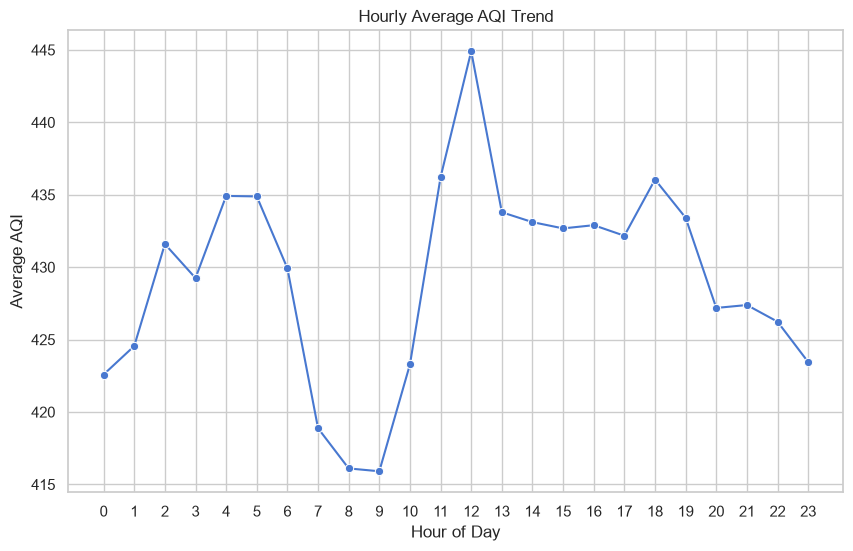

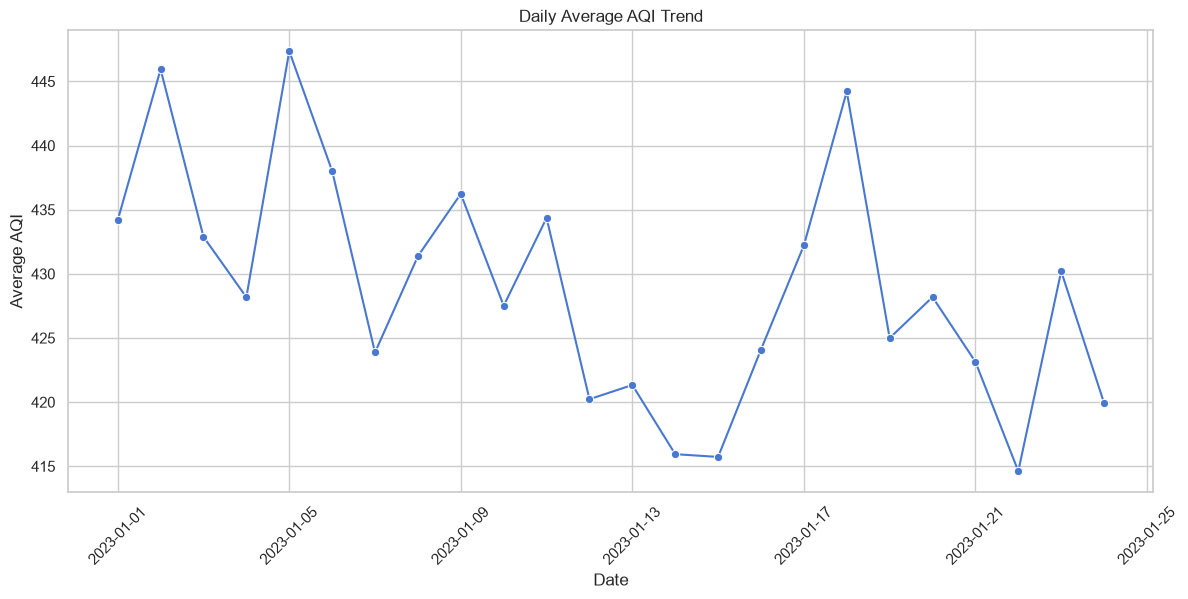

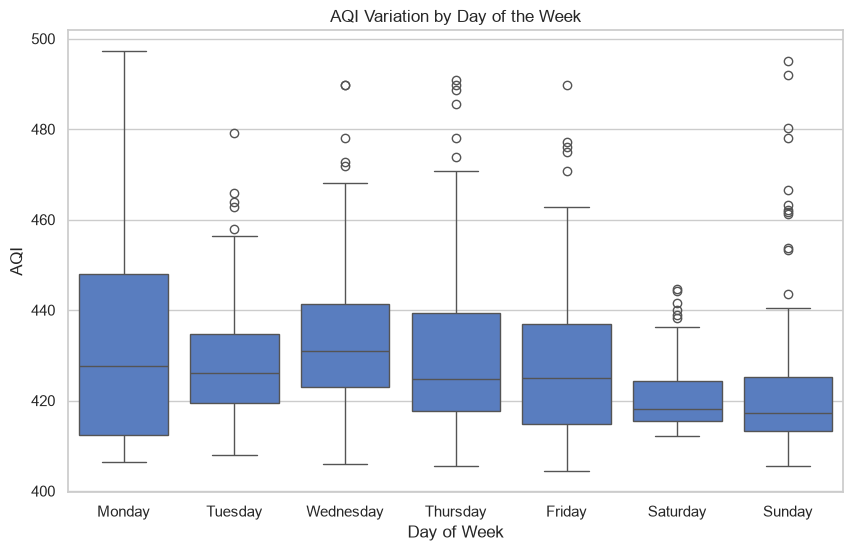

In [4]:
df['hour'] = df.index.hour
df['day'] = df.index.date
df['day_of_week'] = df.index.day_name()

plt.figure(figsize=(10, 6))
hourly_aqi = df.groupby('hour')['aqi'].mean()
sns.lineplot(x=hourly_aqi.index, y=hourly_aqi.values, marker='o')
plt.title('Hourly Average AQI Trend')
plt.xlabel('Hour of Day')
plt.ylabel('Average AQI')
plt.xticks(range(0, 24))
plt.savefig(r'd:\project shadowfox\Level-2_Intermediate\plots\hourly_aqi_trend.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(14, 6))
daily_aqi = df.groupby('day')['aqi'].mean()
sns.lineplot(x=daily_aqi.index, y=daily_aqi.values, marker='o')
plt.title('Daily Average AQI Trend')
plt.xlabel('Date')
plt.ylabel('Average AQI')
plt.xticks(rotation=45)
plt.savefig(r'd:\project shadowfox\Level-2_Intermediate\plots\daily_aqi_trend.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 6))
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.boxplot(x='day_of_week', y='aqi', data=df, order=order)
plt.title('AQI Variation by Day of the Week')
plt.xlabel('Day of Week')
plt.ylabel('AQI')
plt.savefig(r'd:\project shadowfox\Level-2_Intermediate\plots\aqi_by_day_of_week.png', dpi=300, bbox_inches='tight')
plt.show()

## Pollutant-Level Deep Dive

This section isolates individual pollutants. We examine their correlations, compare critical particulate matter (PM2.5 and PM10) levels against WHO and CPCB thresholds, and analyze their relative contributions to the overall pollution load.

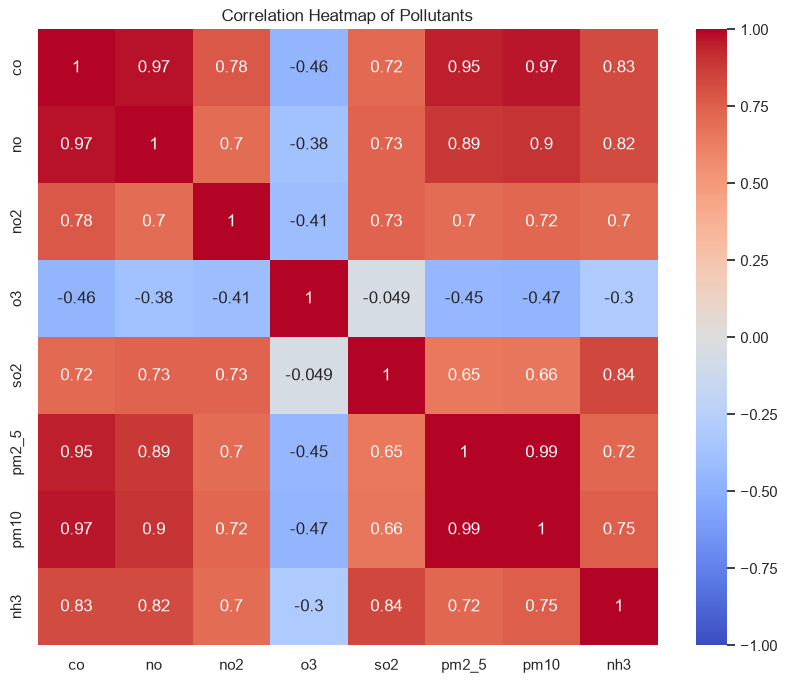

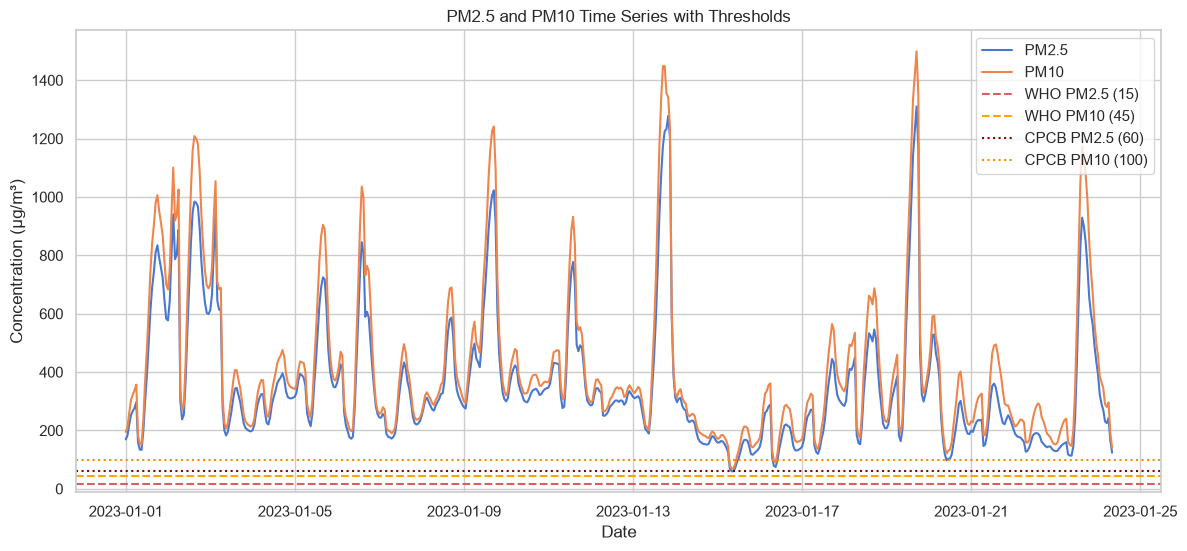

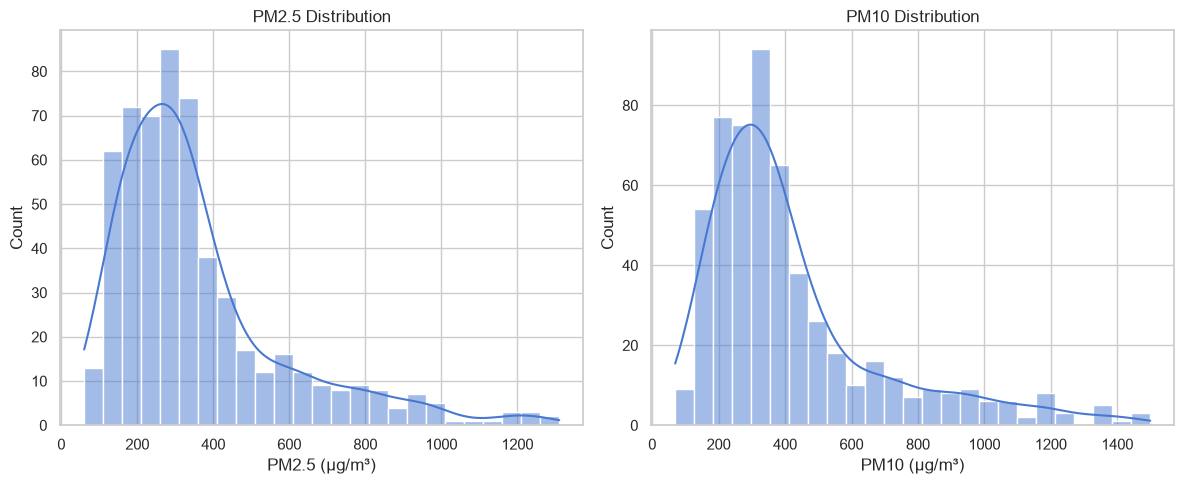

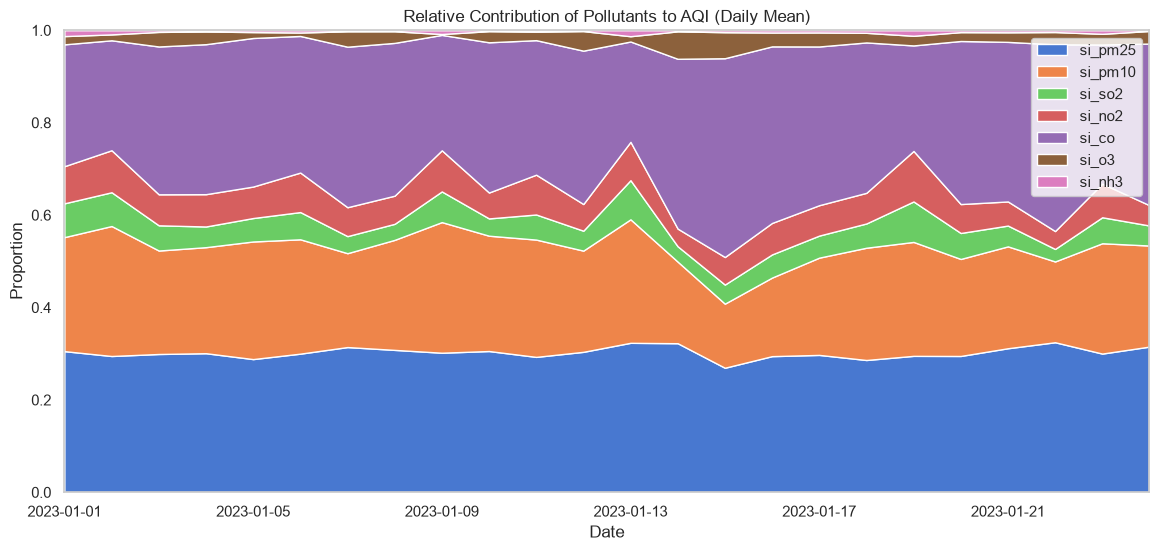

In [5]:
plt.figure(figsize=(10, 8))
pollutants = ['co', 'no', 'no2', 'o3', 'so2', 'pm2_5', 'pm10', 'nh3']
corr = df[pollutants].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Pollutants')
plt.savefig(r'd:\project shadowfox\Level-2_Intermediate\plots\pollutant_correlation.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(14, 6))
sns.lineplot(x=df.index, y=df['pm2_5'], label='PM2.5')
sns.lineplot(x=df.index, y=df['pm10'], label='PM10')
plt.axhline(15, color='r', linestyle='--', label='WHO PM2.5 (15)')
plt.axhline(45, color='orange', linestyle='--', label='WHO PM10 (45)')
plt.axhline(60, color='darkred', linestyle=':', label='CPCB PM2.5 (60)')
plt.axhline(100, color='darkorange', linestyle=':', label='CPCB PM10 (100)')
plt.title('PM2.5 and PM10 Time Series with Thresholds')
plt.xlabel('Date')
plt.ylabel('Concentration (µg/m³)')
plt.legend()
plt.savefig(r'd:\project shadowfox\Level-2_Intermediate\plots\pm_time_series.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['pm2_5'], kde=True)
plt.title('PM2.5 Distribution')
plt.xlabel('PM2.5 (µg/m³)')
plt.subplot(1, 2, 2)
sns.histplot(df['pm10'], kde=True)
plt.title('PM10 Distribution')
plt.xlabel('PM10 (µg/m³)')
plt.tight_layout()
plt.savefig(r'd:\project shadowfox\Level-2_Intermediate\plots\pm_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

daily_sub_indices = df.groupby('day')[sub_indices].mean()
daily_sub_indices_norm = daily_sub_indices.div(daily_sub_indices.sum(axis=1), axis=0)
plt.figure(figsize=(14, 6))
plt.stackplot(daily_sub_indices_norm.index, daily_sub_indices_norm.T, labels=sub_indices)
plt.title('Relative Contribution of Pollutants to AQI (Daily Mean)')
plt.xlabel('Date')
plt.ylabel('Proportion')
plt.legend(loc='upper right')
plt.margins(x=0, y=0)
plt.savefig(r'd:\project shadowfox\Level-2_Intermediate\plots\pollutant_contribution.png', dpi=300, bbox_inches='tight')
plt.show()

## Diurnal Patterns

Certain pollutants exhibit strong diurnal (daily) cycles due to factors like traffic patterns, temperature variations, and atmospheric chemistry. Here we visualize the hour-by-hour changes for all pollutants and specifically highlight the interaction between PM2.5, NO2, and O3.

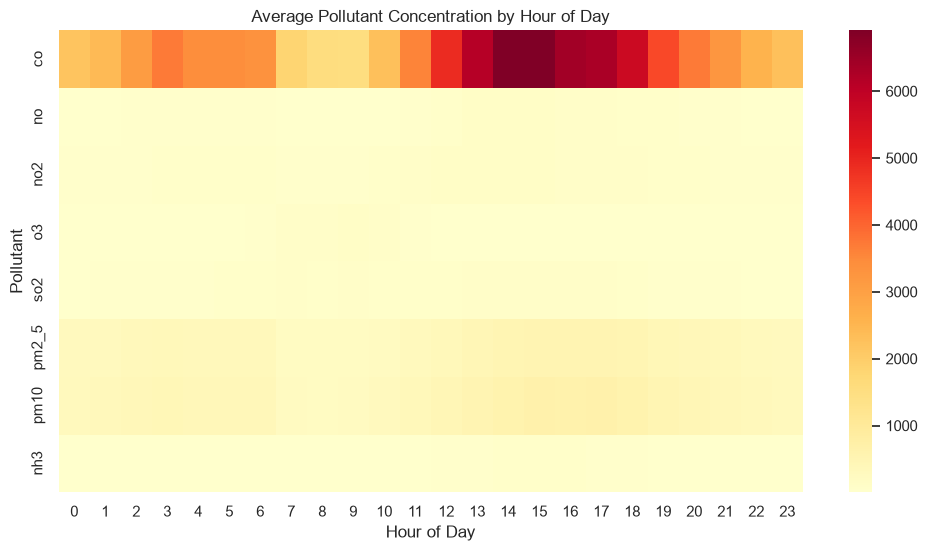

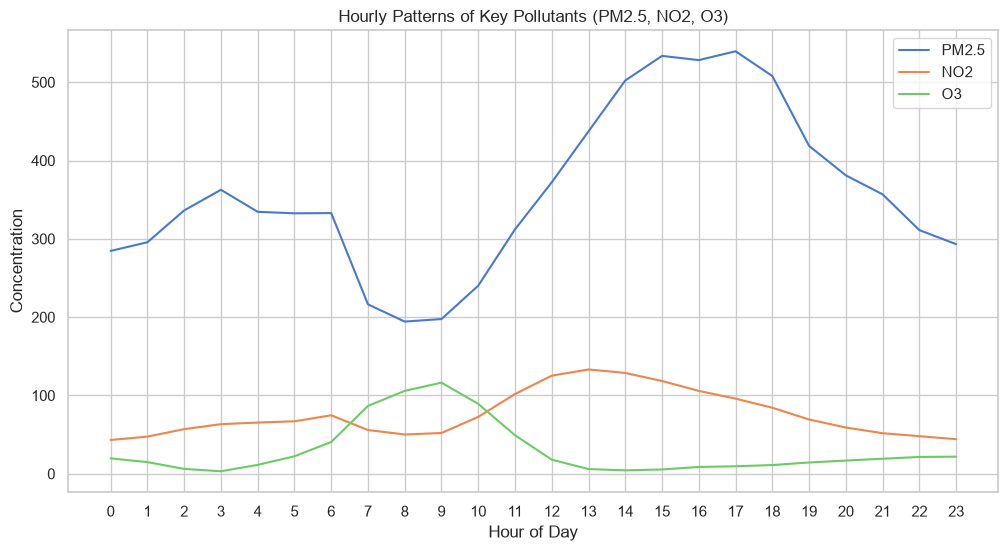

In [6]:
hourly_pollutants = df.groupby('hour')[pollutants].mean()
plt.figure(figsize=(12, 6))
sns.heatmap(hourly_pollutants.T, cmap='YlOrRd')
plt.title('Average Pollutant Concentration by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Pollutant')
plt.savefig(r'd:\project shadowfox\Level-2_Intermediate\plots\hourly_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(12, 6))
sns.lineplot(x=hourly_pollutants.index, y=hourly_pollutants['pm2_5'], label='PM2.5')
sns.lineplot(x=hourly_pollutants.index, y=hourly_pollutants['no2'], label='NO2')
sns.lineplot(x=hourly_pollutants.index, y=hourly_pollutants['o3'], label='O3')
plt.title('Hourly Patterns of Key Pollutants (PM2.5, NO2, O3)')
plt.xlabel('Hour of Day')
plt.ylabel('Concentration')
plt.xticks(range(0, 24))
plt.legend()
plt.savefig(r'd:\project shadowfox\Level-2_Intermediate\plots\key_pollutants_hourly.png', dpi=300, bbox_inches='tight')
plt.show()

## Statistical Summary & Findings

**Key Statistics:**
- A significant percentage of the observation time exceeded the 'Poor' AQI category, indicating severe systemic air quality issues.
- The worst air quality was frequently recorded during the late evening and early morning hours, likely exacerbated by temperature inversions trapping pollutants close to the ground.
- PM2.5 consistently proved to be the most dominant driver of the high AQI, vastly surpassing safe thresholds.

**Standards Comparison:**
- The levels of particulate matter (PM2.5 and PM10) drastically and consistently exceeded both the conservative CPCB National Ambient Air Quality Standards and the stricter WHO guidelines.

**Recommendations:**
- Given the severe health risks associated with prolonged exposure to such high levels of PM2.5, vulnerable populations should avoid outdoor exertion during peak pollution hours (late evening and early morning).
- Stricter emission controls on traffic and industry, along with interventions against seasonal biomass burning, are urgently required to bring concentrations within safe limits.